<a href="https://colab.research.google.com/github/AsfandyarFarooqi/learning-log/blob/main/week08_drive.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [18]:
import os
from google.colab import userdata

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
print("token found, length:", len(os.environ["KAGGLE_API_TOKEN"]))

!pip install -q --upgrade kagglehub
import kagglehub

comp = "smartphone-decimeter-2023"
trace = "sdc2023/train/2023-09-07-18-59-us-ca/pixel7pro/"
gnss_path = kagglehub.competition_download(comp, path=trace + "device_gnss.csv")
truth_path = kagglehub.competition_download(comp, path=trace + "ground_truth.csv")
print(gnss_path)
print(truth_path)

token found, length: 37
/root/.cache/kagglehub/competitions/smartphone-decimeter-2023/sdc2023/train/2023-09-07-18-59-us-ca/pixel7pro/device_gnss.csv
/root/.cache/kagglehub/competitions/smartphone-decimeter-2023/sdc2023/train/2023-09-07-18-59-us-ca/pixel7pro/ground_truth.csv


In [19]:
import numpy as np
np.set_printoptions(suppress=True)

a_earth = 6378137.0
f = 1 / 298.257223563
e2 = 2 * f - f**2
omega = 0.000072921151467
c = 299792458.0

def geodetic_to_ecef(lat_deg, lon_deg, h):
    lat = np.radians(lat_deg)
    lon = np.radians(lon_deg)
    nu = a_earth / np.sqrt(1 - e2 * np.sin(lat)**2)
    X = (nu + h) * np.cos(lat) * np.cos(lon)
    Y = (nu + h) * np.cos(lat) * np.sin(lon)
    Z = (nu * (1 - e2) + h) * np.sin(lat)
    return np.array([X, Y, Z])

def enu_matrix(lat_deg, lon_deg):
    lat = np.radians(lat_deg)
    lon = np.radians(lon_deg)
    east = [-np.sin(lon), np.cos(lon), 0.0]
    north = [-np.sin(lat) * np.cos(lon), -np.sin(lat) * np.sin(lon), np.cos(lat)]
    up = [np.cos(lat) * np.cos(lon), np.cos(lat) * np.sin(lon), np.sin(lat)]
    return np.array([east, north, up])

def gnss_3d(sats, rho, x0, stop=0.0001, max_rounds=10, show=True):
    x = np.array(x0, dtype=float)
    num_sats = len(rho)
    for round_no in range(1, max_rounds + 1):
        diff = x[:3] - sats
        dist0 = np.sqrt(np.sum(diff**2, axis=1))
        A = np.ones((num_sats, 4))
        A[:, :3] = diff / dist0.reshape(num_sats, 1)
        drho = rho - (dist0 + x[3])
        dx = np.linalg.solve(A.T @ A, A.T @ drho)
        x = x + dx
        magnitude = np.sqrt(np.sum(dx**2))
        if show:
            print("round", round_no, "| magnitude of move:", round(magnitude, 3), "m | X, Y, Z, b:", np.round(x, 3))
        if magnitude < stop:
            break
    return x

def turn_sats(sats, x):
    dist = np.sqrt(np.sum((sats - x[:3])**2, axis=1))
    tau = dist / c
    theta = omega * tau
    sat_X = sats[:, 0]
    sat_Y = sats[:, 1]
    new_X = sat_X * np.cos(theta) + sat_Y * np.sin(theta)
    new_Y = -sat_X * np.sin(theta) + sat_Y * np.cos(theta)
    return np.column_stack([new_X, new_Y, sats[:, 2]])

def solve_second(rows):
    sats_t = rows[["SvPositionXEcefMeters", "SvPositionYEcefMeters", "SvPositionZEcefMeters"]].to_numpy()
    rho_t = (rows["RawPseudorangeMeters"] + rows["SvClockBiasMeters"]
             - rows["IonosphericDelayMeters"] - rows["TroposphericDelayMeters"]).to_numpy()
    x = gnss_3d(sats_t, rho_t, np.zeros(4), show=False)
    x = gnss_3d(turn_sats(sats_t, x), rho_t, x, show=False)
    return x

print("setup done")

setup done


In [20]:
import pandas as pd

gnss_df = pd.read_csv(gnss_path)
truth_df = pd.read_csv(truth_path)
gps = gnss_df[gnss_df["SignalType"] == "GPS_L1_CA"]
cols = ["SvPositionXEcefMeters", "SvPositionYEcefMeters", "SvPositionZEcefMeters",
        "RawPseudorangeMeters", "SvClockBiasMeters", "IonosphericDelayMeters", "TroposphericDelayMeters"]
gps = gps.dropna(subset=cols)
times = gps["utcTimeMillis"].unique()
print("GPS L1 rows:", len(gps), "| epochs:", len(times))
print("first and last epoch (ms since 1970):", times.min(), times.max())

t_check = 1694113198000
rows = gps[gps["utcTimeMillis"] == t_check]
x = solve_second(rows)
tr = truth_df[truth_df["UnixTimeMillis"] == t_check]
lat = tr["LatitudeDegrees"].to_numpy()[0]
lon = tr["LongitudeDegrees"].to_numpy()[0]
h = tr["AltitudeMeters"].to_numpy()[0]
truth = geodetic_to_ecef(lat, lon, h)
d = x[:3] - truth
R = enu_matrix(lat, lon)
err = R @ d
print("check epoch | east, north, up (m):", np.round(err, 2), "| magnitude:", round(np.sqrt(np.sum(err**2)), 2), "m")

GPS L1 rows: 11508 | epochs: 1175
first and last epoch (ms since 1970): 1694113197000 1694114371000
check epoch | east, north, up (m): [-8.44 -7.68  4.7 ] | magnitude: 12.34 m


/tmp/ipykernel_1573/2846412673.py:3: DtypeWarning: Columns (21) have mixed types. Specify dtype option on import or set low_memory=False.
  gnss_df = pd.read_csv(gnss_path)


In [21]:
cols = ["SvPositionXEcefMeters", "SvPositionYEcefMeters", "SvPositionZEcefMeters",
        "RawPseudorangeMeters", "SvClockBiasMeters", "IonosphericDelayMeters", "TroposphericDelayMeters"]
print("empty cells in each column the solver needs:")
print(gps[cols].isna().sum())
gps = gps.dropna(subset=cols)

times = gps["utcTimeMillis"].unique()
counts = gps["utcTimeMillis"].value_counts()
minutes = (times.max() - times.min()) / 1000 / 60
print("GPS L1 rows:", len(gps), "| epochs:", len(times))
print("first and last epoch (ms since 1970):", times.min(), times.max())
print("drive length:", round(minutes, 2), "min")
print("GPS L1 satellites per epoch: fewest", counts.min(), "| most", counts.max())
print("epochs with fewer than 4:", (counts < 4).sum())

empty cells in each column the solver needs:
SvPositionXEcefMeters      0
SvPositionYEcefMeters      0
SvPositionZEcefMeters      0
RawPseudorangeMeters       0
SvClockBiasMeters          0
IonosphericDelayMeters     0
TroposphericDelayMeters    0
dtype: int64
GPS L1 rows: 11508 | epochs: 1175
first and last epoch (ms since 1970): 1694113197000 1694114371000
drive length: 19.57 min
GPS L1 satellites per epoch: fewest 6 | most 10
epochs with fewer than 4: 0


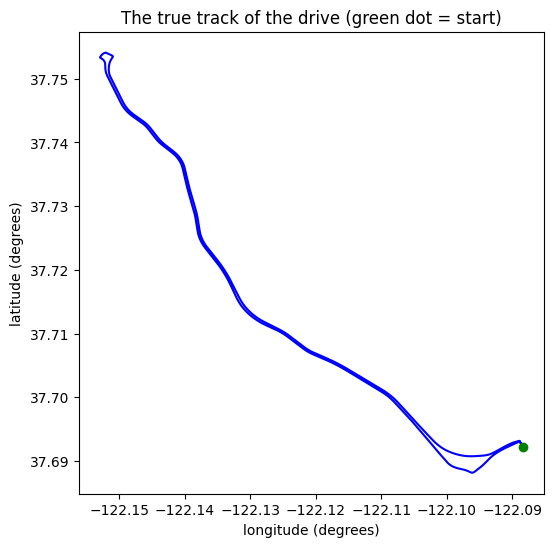

In [22]:
import matplotlib.pyplot as plt

lons = truth_df["LongitudeDegrees"].to_numpy()
lats = truth_df["LatitudeDegrees"].to_numpy()
plt.figure(figsize=(6, 6))
plt.plot(lons, lats, "b-")
plt.plot(lons[0], lats[0], "go")
plt.xlabel("longitude (degrees)")
plt.ylabel("latitude (degrees)")
plt.title("The true track of the drive (green dot = start)")
plt.show()

In [23]:
truth_data=truth_df
print(truth_data.shape)
drive_length=(truth_data['UnixTimeMillis'].unique().max()-truth_data['UnixTimeMillis'].min())/1000/60
print('Drive Length(min): ',drive_length)
top_speed=truth_data['SpeedMps'].max()
top_speed_kmph=top_speed*3.6
print('Top Speed(m/s): ',top_speed)
print('Top Speed(kmph): ',top_speed_kmph)

(1174, 13)
Drive Length(min):  19.55
Top Speed(m/s):  30.261084
Top Speed(kmph):  108.93990240000001


In [24]:
S = np.array([-14857521.248, -20089613.837, 9476798.338])
P = np.array([-2684515.977, -4281395.597, 3878479.201])
G = np.zeros(3)
L = np.sqrt(np.sum((S - G)**2))
u = (S - G) / L
proj = np.sum(u * (P - G))
step = np.sqrt(np.sum((P - G)**2))
w = np.sqrt(step**2 - proj**2)
predicted_SP = L - proj
true_SP = np.sqrt(np.sum((S - P)**2))
print("L:", round(L / 1000, 1), "km | proj:", round(proj / 1000, 1), "km | w:", round(w / 1000, 1), "km")
print("prediction:", round(predicted_SP / 1000, 1), "km | truth:", round(true_SP / 1000, 1), "km | linearisation error:", round((true_SP - predicted_SP) / 1000, 1), "km")

L: 26723.6 km | proj: 6086.5 km | w: 1880.0 km
prediction: 20637.1 km | truth: 20722.5 km | linearisation error: 85.5 km


In [25]:
import numpy as np

sats_2d = np.array([[0.0, 0.0], [10.0, 0.0]])
rho_2d = np.array([5.0, np.sqrt(65.0)])
P_true = np.array([3.0, 4.0])
x = np.array([2.0, 2.0])
print("measured distances (fixed):", np.round(rho_2d, 4))

for round_no in range(1, 5):
    diff = x - sats_2d
    dist0 = np.sqrt(np.sum(diff**2, axis=1))
    A = diff / dist0.reshape(2, 1)
    drho = rho_2d - dist0
    dx = np.linalg.solve(A, drho)
    print("round", round_no, "| guess x:", np.round(x, 4))
    print("   computed distances from x:", np.round(dist0, 4), "| measured minus computed:", np.round(drho, 4) + 0.0)
    x = x + dx
    print("   step dx:", np.round(dx, 4) + 0.0, "| new x:", np.round(x, 4), "| new x is off by:", round(np.sqrt(np.sum((x - P_true)**2)), 4))

measured distances (fixed): [5.     8.0623]
round 1 | guess x: [2. 2.]
   computed distances from x: [2.8284 8.2462] | measured minus computed: [ 2.1716 -0.184 ]
   step dx: [0.7659 2.3052] | new x: [2.7659 4.3052] | new x is off by: 0.3846
round 2 | guess x: [2.7659 4.3052]
   computed distances from x: [5.1171 8.4182] | measured minus computed: [-0.1171 -0.356 ]
   step dx: [ 0.2397 -0.2932] | new x: [3.0057 4.012 ] | new x is off by: 0.0132
round 3 | guess x: [3.0057 4.012 ]
   computed distances from x: [5.013  8.0633] | measured minus computed: [-0.013 -0.001]
   step dx: [-0.0057 -0.012 ] | new x: [3. 4.] | new x is off by: 0.0
round 4 | guess x: [3. 4.]
   computed distances from x: [5.     8.0623] | measured minus computed: [0. 0.]
   step dx: [0. 0.] | new x: [3. 4.] | new x is off by: 0.0


In [26]:
L_warm = true_SP
step_warm = 30.0
print("L_warm:", round(L_warm, 1), "m")
for proj_try in [30.0, 25.0, 15.0, 0.0]:
    w_try = np.sqrt(step_warm**2 - proj_try**2)
    predicted_try = L_warm - proj_try
    true_try = np.sqrt((L_warm - proj_try)**2 + w_try**2)
    print("proj:", proj_try, "m | w:", round(w_try, 2), "m | linearisation error:", round((true_try - predicted_try) * 1000, 4), "mm")

L_warm: 20722523.9 m
proj: 30.0 m | w: 0.0 m | linearisation error: 0.0 mm
proj: 25.0 m | w: 16.58 m | linearisation error: 0.0066 mm
proj: 15.0 m | w: 25.98 m | linearisation error: 0.0163 mm
proj: 0.0 m | w: 30.0 m | linearisation error: 0.0217 mm


In [27]:
x1 = solve_second(gps[gps["utcTimeMillis"] == 1694113198000])
rows2 = gps[gps["utcTimeMillis"] == 1694113199000]
sats2 = rows2[["SvPositionXEcefMeters", "SvPositionYEcefMeters", "SvPositionZEcefMeters"]].to_numpy()
rho2 = (rows2["RawPseudorangeMeters"] + rows2["SvClockBiasMeters"]
        - rows2["IonosphericDelayMeters"] - rows2["TroposphericDelayMeters"]).to_numpy()
sats2_fixed = turn_sats(sats2, x1)
print("epoch 1 answer x1:", np.round(x1, 3))
print("--- epoch 2, cold start (the Earth's centre):")
x2_cold = gnss_3d(sats2_fixed, rho2, np.zeros(4))
print("--- epoch 2, warm start (epoch 1's answer):")
x2_warm = gnss_3d(sats2_fixed, rho2, x1)
print("largest difference between the two answers (m):", round(np.max(np.abs(x2_cold - x2_warm)), 6))

epoch 1 answer x1: [-2684518.466 -4281395.239  3878478.488       20.002]
--- epoch 2, cold start (the Earth's centre):
round 1 | magnitude of move: 7572908.046 m | X, Y, Z, b: [-3166494.611 -5042728.768  4524421.278  1192789.516]
round 2 | magnitude of move: 1588851.931 m | X, Y, Z, b: [-2695834.458 -4299431.599  3892261.574    30544.745]
round 3 | magnitude of move: 39653.785 m | X, Y, Z, b: [-2684522.399 -4281405.731  3878486.428       52.558]
round 4 | magnitude of move: 21.57 m | X, Y, Z, b: [-2684515.977 -4281395.597  3878479.201       36.155]
round 5 | magnitude of move: 0.0 m | X, Y, Z, b: [-2684515.977 -4281395.597  3878479.201       36.155]
--- epoch 2, warm start (epoch 1's answer):
round 1 | magnitude of move: 16.363 m | X, Y, Z, b: [-2684515.977 -4281395.597  3878479.201       36.155]
round 2 | magnitude of move: 0.0 m | X, Y, Z, b: [-2684515.977 -4281395.597  3878479.201       36.155]
largest difference between the two answers (m): 0.0


In [28]:
def solve_epoch(rows, x_start):
    sats_t = rows[["SvPositionXEcefMeters", "SvPositionYEcefMeters", "SvPositionZEcefMeters"]].to_numpy()
    rho_t = (rows["RawPseudorangeMeters"] + rows["SvClockBiasMeters"]
             - rows["IonosphericDelayMeters"] - rows["TroposphericDelayMeters"]).to_numpy()
    x = gnss_3d(sats_t, rho_t, x_start, show=False)
    x = gnss_3d(turn_sats(sats_t, x), rho_t, x, show=False)
    return x

x_prev = np.zeros(4)
errors = []
skipped = 0
for t in times:
    rows = gps[gps["utcTimeMillis"] == t]
    tr = truth_df[truth_df["UnixTimeMillis"] == t]
    if len(rows) < 4 or len(tr) == 0:
        skipped = skipped + 1
        continue
    x = solve_epoch(rows, x_prev)
    x_prev = x
    lat = tr["LatitudeDegrees"].to_numpy()[0]
    lon = tr["LongitudeDegrees"].to_numpy()[0]
    h = tr["AltitudeMeters"].to_numpy()[0]
    d_t = x[:3] - geodetic_to_ecef(lat, lon, h)
    err_t = enu_matrix(lat, lon) @ d_t
    errors.append(np.sqrt(np.sum(err_t**2)))

errors = np.array(errors)
rmse = np.sqrt(np.mean(errors**2))
print("epochs solved:", len(errors), "| skipped:", skipped)
print("first 5 error magnitudes (m):", np.round(errors[:5], 2))
print("largest error:", round(np.max(errors), 2), "m")
print("mean:", round(np.mean(errors), 2), "m | RMSE:", round(rmse, 2), "m")

epochs solved: 1174 | skipped: 1
first 5 error magnitudes (m): [12.34  9.93  9.47  9.86  8.81]
largest error: 65.93 m
mean: 9.74 m | RMSE: 11.73 m


In [29]:
t_check = 1694113198000
rows = gps[gps["utcTimeMillis"] == t_check]
svid = rows["Svid"].to_numpy()
sats_t = rows[["SvPositionXEcefMeters", "SvPositionYEcefMeters", "SvPositionZEcefMeters"]].to_numpy()
raw = rows["RawPseudorangeMeters"].to_numpy()
sat_clock = rows["SvClockBiasMeters"].to_numpy()
iono = rows["IonosphericDelayMeters"].to_numpy()
tropo = rows["TroposphericDelayMeters"].to_numpy()
rho_t = raw + sat_clock - iono - tropo
num_sats = len(rho_t)
print("number of satellites n:", num_sats)
for i in range(num_sats):
    from_centre = np.sqrt(np.sum(sats_t[i]**2))
    print(f"satellite {svid[i]:2d} | from the Earth's centre: {from_centre / 1000:.1f} km | "
          f"rho = {raw[i]:.3f} {sat_clock[i]:+.3f} {-iono[i]:+.3f} {-tropo[i]:+.3f} = {rho_t[i]:.3f} m")

number of satellites n: 10
satellite  2 | from the Earth's centre: 26911.9 km | rho = 24567440.915 -166876.028 -9.277 -8.645 = 24400546.965 m
satellite  8 | from the Earth's centre: 26658.7 km | rho = 22397058.939 -42304.128 -6.805 -4.165 = 22354743.841 m
satellite 10 | from the Earth's centre: 26706.1 km | rho = 20864402.974 -15721.262 -4.827 -2.784 = 20848674.101 m
satellite 18 | from the Earth's centre: 26462.5 km | rho = 23472434.871 -122784.859 -10.145 -6.487 = 23349633.380 m
satellite 21 | from the Earth's centre: 26857.0 km | rho = 23502523.242 +44763.811 -8.076 -5.885 = 23547273.092 m
satellite 23 | from the Earth's centre: 26510.4 km | rho = 22386395.921 +19570.306 -7.199 -4.434 = 22405954.594 m
satellite 24 | from the Earth's centre: 26183.5 km | rho = 23822439.568 -93804.429 -9.803 -9.052 = 23728616.285 m
satellite 27 | from the Earth's centre: 26711.1 km | rho = 21815989.505 -10684.238 -6.232 -3.519 = 21805295.516 m
satellite 28 | from the Earth's centre: 26571.8 km | rho =

In [30]:
x_centre = np.zeros(4)                              # initial guess (X, Y, Z, b): the Earth's centre, b = 0
diff = x_centre[:3] - sats_t                        # (X - X_sat_i, Y - Y_sat_i, Z - Z_sat_i)
dist0 = np.sqrt(np.sum(diff**2, axis=1))            # (3) dist0_i
predicted = dist0 + x_centre[3]                     # (3) predicted_i = dist0_i + b
A = np.ones((num_sats, 4))
A[:, :3] = diff / dist0.reshape(num_sats, 1)        # (4) and (6): rows A_i = (u_i, 1)
drho = rho_t - predicted                            # (6) drho_i = rho_i - predicted_i
dx = np.linalg.solve(A.T @ A, A.T @ drho)           # (7) normal equations
v = drho - A @ dx                                   # (7) residuals v_i
x_after1 = x_centre + dx                            # (8) the next trial point
for i in range(num_sats):
    print(f"satellite {svid[i]:2d} | (3) dist0 {dist0[i] / 1000:8.1f} km | (6) drho {drho[i] / 1000:7.1f} km | (7) v {v[i] / 1000:6.1f} km")
print("(6) row A_1 (satellite 2):", np.round(A[0], 4))
print("(7) dx (m):", np.round(dx, 3))
print("(8) after round 1:", np.round(x_after1, 3))
print("(8) magnitude of dx:", round(float(np.sqrt(np.sum(dx**2))), 3), "m")

satellite  2 | (3) dist0  26911.9 km | (6) drho -2511.4 km | (7) v  -27.4 km
satellite  8 | (3) dist0  26658.7 km | (6) drho -4303.9 km | (7) v   36.6 km
satellite 10 | (3) dist0  26706.1 km | (6) drho -5857.4 km | (7) v  -48.4 km
satellite 18 | (3) dist0  26462.5 km | (6) drho -3112.9 km | (7) v   47.9 km
satellite 21 | (3) dist0  26857.0 km | (6) drho -3309.7 km | (7) v   13.0 km
satellite 23 | (3) dist0  26510.4 km | (6) drho -4104.5 km | (7) v   32.7 km
satellite 24 | (3) dist0  26183.5 km | (6) drho -2454.9 km | (7) v  -12.8 km
satellite 27 | (3) dist0  26711.1 km | (6) drho -4905.8 km | (7) v   36.8 km
satellite 28 | (3) dist0  26571.8 km | (6) drho -1622.8 km | (7) v  -40.5 km
satellite 32 | (3) dist0  26723.5 km | (6) drho -6000.7 km | (7) v  -37.9 km
(6) row A_1 (satellite 2): [ 0.5543 -0.3115 -0.7719  1.    ]
(7) dx (m): [-3166453.963 -5042663.62   4524330.896  1192685.472]
(8) after round 1: [-3166453.963 -5042663.62   4524330.896  1192685.472]
(8) magnitude of dx: 7572777.2

In [31]:
print("--- first solve, from the Earth's centre:")
x_first = gnss_3d(sats_t, rho_t, np.zeros(4))
sats_turned = turn_sats(sats_t, x_first)
print("--- second solve, satellites turned for the Earth's rotation, starting from the first answer:")
x_answer = gnss_3d(sats_turned, rho_t, x_first)
print("magnitude of the exact move from the Earth's centre to the answer:", round(float(np.sqrt(np.sum(x_answer**2))), 3), "m")
v_final = rho_t - (np.sqrt(np.sum((x_answer[:3] - sats_turned)**2, axis=1)) + x_answer[3])
print("residuals after the last round (m):", np.round(v_final, 2))
d = x_answer[:3] - truth
err = enu_matrix(lat, lon) @ d
print("error east, north, up (m):", np.round(err, 2), "| magnitude:", round(float(np.sqrt(np.sum(err**2))), 2), "m")

--- first solve, from the Earth's centre:
round 1 | magnitude of move: 7572777.283 m | X, Y, Z, b: [-3166453.963 -5042663.62   4524330.896  1192685.472]
round 2 | magnitude of move: 1588721.413 m | X, Y, Z, b: [-2695811.359 -4299439.968  3892254.126    30519.895]
round 3 | magnitude of move: 39641.377 m | X, Y, Z, b: [-2684501.163 -4281420.863  3878485.227       36.334]
round 4 | magnitude of move: 21.552 m | X, Y, Z, b: [-2684494.744 -4281410.737  3878478.008       19.944]
round 5 | magnitude of move: 0.0 m | X, Y, Z, b: [-2684494.744 -4281410.737  3878478.008       19.944]
--- second solve, satellites turned for the Earth's rotation, starting from the first answer:
round 1 | magnitude of move: 28.34 m | X, Y, Z, b: [-2684518.466 -4281395.239  3878478.488       20.002]
round 2 | magnitude of move: 0.0 m | X, Y, Z, b: [-2684518.466 -4281395.239  3878478.488       20.002]
magnitude of the exact move from the Earth's centre to the answer: 6370210.355 m
residuals after the last round (m):

In [32]:
x1 = solve_second(gps[gps["utcTimeMillis"] == 1694113198000])
rows2 = gps[gps["utcTimeMillis"] == 1694113199000]
sats2 = rows2[["SvPositionXEcefMeters", "SvPositionYEcefMeters", "SvPositionZEcefMeters"]].to_numpy()
rho2 = (rows2["RawPseudorangeMeters"] + rows2["SvClockBiasMeters"]
        - rows2["IonosphericDelayMeters"] - rows2["TroposphericDelayMeters"]).to_numpy()
sats2_fixed = turn_sats(sats2, x1)
print("epoch 1 answer x1:", np.round(x1, 3))
print("--- epoch 2, cold start (the Earth's centre):")
x2_cold = gnss_3d(sats2_fixed, rho2, np.zeros(4))
print("--- epoch 2, warm start (epoch 1's answer):")
x2_warm = gnss_3d(sats2_fixed, rho2, x1)
print("largest difference between the two answers (m):", round(np.max(np.abs(x2_cold - x2_warm)), 6))

epoch 1 answer x1: [-2684518.466 -4281395.239  3878478.488       20.002]
--- epoch 2, cold start (the Earth's centre):
round 1 | magnitude of move: 7572908.046 m | X, Y, Z, b: [-3166494.611 -5042728.768  4524421.278  1192789.516]
round 2 | magnitude of move: 1588851.931 m | X, Y, Z, b: [-2695834.458 -4299431.599  3892261.574    30544.745]
round 3 | magnitude of move: 39653.785 m | X, Y, Z, b: [-2684522.399 -4281405.731  3878486.428       52.558]
round 4 | magnitude of move: 21.57 m | X, Y, Z, b: [-2684515.977 -4281395.597  3878479.201       36.155]
round 5 | magnitude of move: 0.0 m | X, Y, Z, b: [-2684515.977 -4281395.597  3878479.201       36.155]
--- epoch 2, warm start (epoch 1's answer):
round 1 | magnitude of move: 16.363 m | X, Y, Z, b: [-2684515.977 -4281395.597  3878479.201       36.155]
round 2 | magnitude of move: 0.0 m | X, Y, Z, b: [-2684515.977 -4281395.597  3878479.201       36.155]
largest difference between the two answers (m): 0.0


In [33]:
def solve_epoch(rows, x_start):
    sats_t = rows[["SvPositionXEcefMeters", "SvPositionYEcefMeters", "SvPositionZEcefMeters"]].to_numpy()
    rho_t = (rows["RawPseudorangeMeters"] + rows["SvClockBiasMeters"]
             - rows["IonosphericDelayMeters"] - rows["TroposphericDelayMeters"]).to_numpy()
    x = gnss_3d(sats_t, rho_t, x_start, show=False)
    x = gnss_3d(turn_sats(sats_t, x), rho_t, x, show=False)
    return x

x_prev = np.zeros(4)
errors = []
skipped = 0
for t in times:
    rows = gps[gps["utcTimeMillis"] == t]
    tr = truth_df[truth_df["UnixTimeMillis"] == t]
    if len(rows) < 4 or len(tr) == 0:
        skipped = skipped + 1
        continue
    x = solve_epoch(rows, x_prev)
    move = np.sqrt(np.sum((x - x_prev)**2))
    x_prev = x
    lat = tr["LatitudeDegrees"].to_numpy()[0]
    lon = tr["LongitudeDegrees"].to_numpy()[0]
    h = tr["AltitudeMeters"].to_numpy()[0]
    d_t = x[:3] - geodetic_to_ecef(lat, lon, h)
    err_t = enu_matrix(lat, lon) @ d_t
    errors.append(np.sqrt(np.sum(err_t**2)))
    if len(errors) <= 100:
        print("epoch", len(errors), "| time", t, "| satellites:", len(rows), "| b:", round(float(x[3]), 3),
              "m | move from the initial guess:", round(float(move), 3), "m | error:", round(float(errors[-1]), 2), "m")

errors = np.array(errors)
rmse = np.sqrt(np.mean(errors**2))
print("epochs solved:", len(errors), "| skipped:", skipped)
print("largest error:", round(np.max(errors), 2), "m")
print("mean:", round(np.mean(errors), 2), "m | RMSE:", round(rmse, 2), "m")

epoch 1 | time 1694113198000 | satellites: 10 | b: 20.002 m | move from the initial guess: 6370210.355 m | error: 12.34 m
epoch 2 | time 1694113199000 | satellites: 10 | b: 36.155 m | move from the initial guess: 16.363 m | error: 9.93 m
epoch 3 | time 1694113200000 | satellites: 10 | b: 52.424 m | move from the initial guess: 16.712 m | error: 9.47 m
epoch 4 | time 1694113201000 | satellites: 10 | b: 74.175 m | move from the initial guess: 23.229 m | error: 9.86 m
epoch 5 | time 1694113202000 | satellites: 10 | b: 89.76 m | move from the initial guess: 15.714 m | error: 8.81 m
epoch 6 | time 1694113203000 | satellites: 10 | b: 107.15 m | move from the initial guess: 17.44 m | error: 8.58 m
epoch 7 | time 1694113204000 | satellites: 10 | b: 124.645 m | move from the initial guess: 17.644 m | error: 10.55 m
epoch 8 | time 1694113205000 | satellites: 10 | b: 139.718 m | move from the initial guess: 15.339 m | error: 10.42 m
epoch 9 | time 1694113206000 | satellites: 10 | b: 158.031 m | m

In [37]:
google_errors = []
for t in times:
    rows = gps[gps["utcTimeMillis"] == t]
    tr = truth_df[truth_df["UnixTimeMillis"] == t]
    if len(rows) < 4 or len(tr) == 0:
        continue
    google_xyz = rows[["WlsPositionXEcefMeters", "WlsPositionYEcefMeters", "WlsPositionZEcefMeters"]].to_numpy()[0]           # Google's X, Y, Z for this epoch, from the epoch's first row
    if np.isnan(google_xyz).any():
        continue
    lat = tr["LatitudeDegrees"].to_numpy()[0]
    lon = tr["LongitudeDegrees"].to_numpy()[0]
    h = tr["AltitudeMeters"].to_numpy()[0]                  # this epoch's true height
    d_google = google_xyz - geodetic_to_ecef(lat,lon,h)              # Google's error vector: google_xyz minus the true X, Y, Z
    err_google = enu_matrix(lat,lon)@d_google            # its east, north, up parts: the rotation matrix R times d_google
    google_errors.append(np.sqrt(np.sum(err_google**2)))   # their magnitude
google_errors = np.array(google_errors)
google_rmse = np.sqrt(np.mean(google_errors**2))
print("first 5 Google errors (m):", np.round(google_errors[:5], 2))
print("Google epochs:", len(google_errors), "| Google mean:", round(np.mean(google_errors), 2), "m | Google RMSE:", round(google_rmse, 2), "m")
print("my RMSE:", round(rmse, 2), "m | Google RMSE:", round(google_rmse, 2), "m")

first 5 Google errors (m): [ 7.97 11.79 11.87 13.72 13.47]
Google epochs: 1174 | Google mean: 10.16 m | Google RMSE: 10.46 m
my RMSE: 11.73 m | Google RMSE: 10.46 m


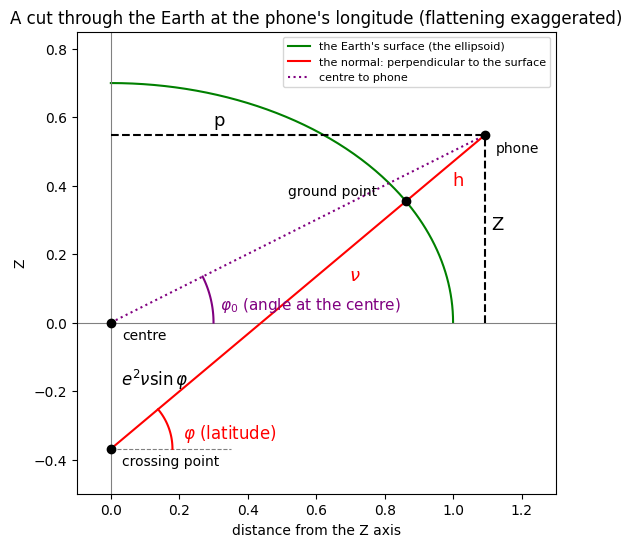

angle at the centre: 26.6 degrees | latitude: 40 degrees


In [38]:
import numpy as np
import matplotlib.pyplot as plt

# a made-up, very flat Earth so the picture shows the effect: equator radius 1, pole radius 0.7
a_pic = 1.0
e2_pic = 1 - 0.7**2                                   # e² = 1 − (pole radius ÷ equator radius)², here 0.51
lat_pic = np.radians(40)                              # the phone's latitude φ
h_pic = 0.3                                           # the phone's height above the ground point

nu_pic = a_pic / np.sqrt(1 - e2_pic * np.sin(lat_pic)**2)                     # (N)
ground = [nu_pic * np.cos(lat_pic), nu_pic * (1 - e2_pic) * np.sin(lat_pic)]  # on the surface, h = 0
phone = [(nu_pic + h_pic) * np.cos(lat_pic), (nu_pic * (1 - e2_pic) + h_pic) * np.sin(lat_pic)]
cross = [0.0, -e2_pic * nu_pic * np.sin(lat_pic)]                             # where the normal meets the Z axis

angle = np.linspace(0, np.pi / 2, 200)
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(a_pic * np.cos(angle), 0.7 * np.sin(angle), color="green", label="the Earth's surface (the ellipsoid)")
ax.axhline(0, color="gray", linewidth=0.8)
ax.axvline(0, color="gray", linewidth=0.8)
ax.plot([cross[0], phone[0]], [cross[1], phone[1]], color="red", label="the normal: perpendicular to the surface")
ax.plot([0, phone[0]], [0, phone[1]], color="purple", linestyle=":", label="centre to phone")
ax.plot([0, phone[0]], [phone[1], phone[1]], color="black", linestyle="--")
ax.plot([phone[0], phone[0]], [0, phone[1]], color="black", linestyle="--")
ax.plot([cross[0], 0.35], [cross[1], cross[1]], color="gray", linestyle="--", linewidth=0.8)
for point, name, shift in [([0, 0], "centre", (8, -12)), (cross, "crossing point", (8, -12)),
                           (ground, "ground point", (-85, 4)), (phone, "phone", (8, -12))]:
    ax.plot(point[0], point[1], "o", color="black")
    ax.annotate(name, point, textcoords="offset points", xytext=shift)
arc_k = np.linspace(0, lat_pic, 50)
ax.plot(cross[0] + 0.18 * np.cos(arc_k), cross[1] + 0.18 * np.sin(arc_k), color="red")
arc_o = np.linspace(0, np.arctan2(phone[1], phone[0]), 50)
ax.plot(0.3 * np.cos(arc_o), 0.3 * np.sin(arc_o), color="purple")
ax.text(0.3, phone[1] + 0.03, "p", fontsize=13)
ax.text(phone[0] + 0.02, phone[1] / 2, "Z", fontsize=13)
ax.text(0.03, cross[1] / 2, r"$e^2 \nu \sin\varphi$", fontsize=12)
ax.text(0.75 * ground[0] + 0.05, cross[1] + 0.75 * (ground[1] - cross[1]) - 0.05, r"$\nu$", fontsize=13, color="red")
ax.text((ground[0] + phone[0]) / 2 + 0.02, (ground[1] + phone[1]) / 2 - 0.05, "h", fontsize=13, color="red")
ax.text(0.21, cross[1] + 0.03, r"$\varphi$ (latitude)", fontsize=12, color="red")
ax.text(0.32, 0.04, r"$\varphi_0$ (angle at the centre)", fontsize=11, color="purple")
ax.set_xlabel("distance from the Z axis")
ax.set_ylabel("Z")
ax.set_title("A cut through the Earth at the phone's longitude (flattening exaggerated)")
ax.set_aspect("equal")
ax.set_xlim(-0.1, 1.3)
ax.set_ylim(-0.5, 0.85)
ax.legend(loc="upper right", fontsize=8)
plt.show()

print("angle at the centre:", round(float(np.degrees(np.arctan2(phone[1], phone[0]))), 1), "degrees | latitude:", 40, "degrees")

In [39]:
def ecef_to_geodetic(xyz, stop=1e-11, max_rounds=10, show=False):
    X, Y, Z = xyz
    lon = np.arctan2(Y, X)                                          # (L1)
    p = np.sqrt(X**2 + Y**2)                                        # (L2)
    lat = np.arctan2(Z, p)                                          # initial guess: the angle at the centre
    if show:
        print(f"round 0 (initial guess) | latitude: {np.degrees(lat):.9f} degrees")
    for round_no in range(1, max_rounds + 1):
        nu = a_earth / np.sqrt(1 - e2 * np.sin(lat)**2)             # (L3)
        lat_new = np.arctan2(Z + e2 * nu * np.sin(lat), p)          # (L4)
        change = abs(lat_new - lat)
        lat = lat_new
        if show:
            print(f"round {round_no} | latitude: {np.degrees(lat):.9f} degrees | change: {change:.2e} radians, about {change * a_earth:.6f} m on the ground")
        if change < stop:
            break
    nu = a_earth / np.sqrt(1 - e2 * np.sin(lat)**2)                 # (L3) at the final latitude
    h = p / np.cos(lat) - nu                                        # (L5)
    return np.degrees(lat), np.degrees(lon), h

print("ecef_to_geodetic ready")

ecef_to_geodetic ready


In [40]:
tr_check = truth_df[truth_df["UnixTimeMillis"] == t_check]
check_lat = tr_check["LatitudeDegrees"].to_numpy()[0]
check_lon = tr_check["LongitudeDegrees"].to_numpy()[0]
check_h = tr_check["AltitudeMeters"].to_numpy()[0]
check_xyz = geodetic_to_ecef(check_lat, check_lon, check_h)
print("truth X, Y, Z (m):", np.round(check_xyz, 3))

lat_back, lon_back, h_back = ecef_to_geodetic(check_xyz, show=True)
print(f"back again | latitude: {lat_back:.9f} | longitude: {lon_back:.9f} | height: {h_back:.4f} m")
print(f"truth file | latitude: {check_lat:.9f} | longitude: {check_lon:.9f} | height: {check_h:.4f} m")
print(f"differences: {lat_back - check_lat:.2e} degrees, {lon_back - check_lon:.2e} degrees, {h_back - check_h:.2e} m")

truth X, Y, Z (m): [-2684506.844 -4281392.596  3878481.691]
round 0 (initial guess) | latitude: 37.506192673 degrees
round 1 | latitude: 37.691448237 degrees | change: 3.23e-03 radians, about 20622.554989 m on the ground
round 2 | latitude: 37.692227711 degrees | change: 1.36e-05 radians, about 86.770622 m on the ground
round 3 | latitude: 37.692230986 degrees | change: 5.72e-08 radians, about 0.364638 m on the ground
round 4 | latitude: 37.692231000 degrees | change: 2.40e-10 radians, about 0.001532 m on the ground
round 5 | latitude: 37.692231000 degrees | change: 1.01e-12 radians, about 0.000006 m on the ground
back again | latitude: 37.692231000 | longitude: -122.088419900 | height: 20.9736 m
truth file | latitude: 37.692231000 | longitude: -122.088419900 | height: 20.9736 m
differences: -2.42e-13 degrees, 0.00e+00 degrees, -2.03e-08 m


In [41]:
X_check, Y_check, Z_check = check_xyz
p_check = np.sqrt(X_check**2 + Y_check**2)
lat_centre = np.degrees(np.arctan2(Z_check, p_check))
d_centre = geodetic_to_ecef(lat_centre, check_lon, check_h) - check_xyz
print(f"angle at the centre: {lat_centre:.6f} degrees | latitude: {check_lat:.6f} degrees")
print(f"a dot at the angle at the centre would be {np.sqrt(np.sum(d_centre**2)):.1f} m from the truth")

print(f"plain arctan(Y / X): {np.degrees(np.arctan(Y_check / X_check)):.6f} degrees")
print(f"atan2(Y, X):         {np.degrees(np.arctan2(Y_check, X_check)):.6f} degrees")

angle at the centre: 37.506193 degrees | latitude: 37.692231 degrees
a dot at the angle at the centre would be 20648.2 m from the truth
plain arctan(Y / X): 57.911580 degrees
atan2(Y, X):         -122.088420 degrees


In [42]:
x = solve_second(gps[gps["utcTimeMillis"] == t_check])
my_lat, my_lon, my_h = ecef_to_geodetic(x[:3])
print(f"mine  | latitude: {my_lat:.7f} | longitude: {my_lon:.7f} | height: {my_h:.2f} m")
print(f"truth | latitude: {check_lat:.7f} | longitude: {check_lon:.7f} | height: {check_h:.2f} m")
print(f"mine − truth: {my_lat - check_lat:.7f} degrees, {my_lon - check_lon:.7f} degrees, {my_h - check_h:.2f} m")

mine  | latitude: 37.6921618 | longitude: -122.0885156 | height: 25.67 m
truth | latitude: 37.6922310 | longitude: -122.0884199 | height: 20.97 m
mine − truth: -0.0000692 degrees, -0.0000957 degrees, 4.70 m
